In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

In [2]:
pth = os.path.join('..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'cancer', 'CCCA')
pth_dev = os.path.join(pth_data, 'development', 'modeling')
pth_ref = os.path.join(pth_data, 'ref', 'AnimalTFDBv4')
pth_fig = os.path.join(pth, 'figures', 'cancer', 'CCCA')
pth_out = os.path.join(pth_data, 'results', 'regulation')

In [3]:
adata_dev = sc.read_h5ad(os.path.join(pth_dev, 'spectrum.h5ad'))
adata = sc.read_h5ad(os.path.join(pth_in, 'spectrum.h5ad'))
adata

AnnData object with n_obs × n_vars = 149645 × 513
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'ebv', 'celltype', 'Title', 'Category', 'Disease', 'Technology', 'Samples', 'Cells', 'Name', 'patient', 'cell_subtype', 'source', 'disease', 'p16_status', 'site', 't_stage', 'n_stage', 'gender', 'race', 'age', 'tobacco_use', 'alcohol_use', 'hpv', 'hpv_score', 'treatment', 'procedure', 'sorting', 'cluster', 'malignant', 'sample_id', 'cell_subtype_clusters', 'tnm_stage', 'viral', 'location', 'cancer_type', 'treatment_exposure', 'treatment_response', 'cell_lineage', 'type', 'clusters_by_authors', 'cell_QCpass', 'is_tumor', 'cell_compartment', 'cluster_assignment', 'metastasis', 'sex', 'prior_enzalutamide', 'prior_abiraterone', 'prior_taxane', 'prior_platinum', 'prior_sipuleucel_T', 'purity', 'has_bulk_RNA', 'cancer_cell_state', 'PSA', 'source_region', 'gleason_score', 'ERG_status', 'cores'

In [4]:
# transcription factors
fn = os.path.join(pth_ref, 'Homo_sapiens_TF')
tf = pd.read_csv(fn, sep = '\t').Symbol
tf = tf.loc[tf.isin(adata.var_names)].values

In [ ]:
# filter small datasets
n = adata.obs.source.value_counts()
src_keep = n.index[n > 100].values
msk = adata.obs.source.isin(src_keep)
adata = adata[msk].copy(); adata

AnnData object with n_obs × n_vars = 148719 × 513
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'ebv', 'celltype', 'Title', 'Category', 'Disease', 'Technology', 'Samples', 'Cells', 'Name', 'patient', 'cell_subtype', 'source', 'disease', 'p16_status', 'site', 't_stage', 'n_stage', 'gender', 'race', 'age', 'tobacco_use', 'alcohol_use', 'hpv', 'hpv_score', 'treatment', 'procedure', 'sorting', 'cluster', 'malignant', 'sample_id', 'cell_subtype_clusters', 'tnm_stage', 'viral', 'location', 'cancer_type', 'treatment_exposure', 'treatment_response', 'cell_lineage', 'type', 'clusters_by_authors', 'cell_QCpass', 'is_tumor', 'cell_compartment', 'cluster_assignment', 'metastasis', 'sex', 'prior_enzalutamide', 'prior_abiraterone', 'prior_taxane', 'prior_platinum', 'prior_sipuleucel_T', 'purity', 'has_bulk_RNA', 'cancer_cell_state', 'PSA', 'source_region', 'gleason_score', 'ERG_status', 'cores'

In [ ]:
# datasets pseudobulk
adata_pb = sc.get.aggregate(adata, 'source', 'mean')
adata_pb

AnnData object with n_obs × n_vars = 61 × 513
    obs: 'source'
    layers: 'mean'

In [11]:
# X: TF expression (mean), source
src = adata_pb.obs_names.copy()
X = adata_pb[:, tf].layers['mean'].copy()
X = StandardScaler().fit_transform(X)
src = pd.get_dummies(src).values.astype(float)
X = np.concatenate((X, src), axis = 1)

# y: late signature (std)
y = (adata.obs.groupby('source', observed = True)
     .late.std().loc[adata_pb.obs_names].values
     .reshape(-1, 1))
y = StandardScaler().fit_transform(y).flatten()

# linear regression (y ~ X)
reg = LinearRegression(fit_intercept = False).fit(X, y)

# TF coefficients (beta)
beta = pd.Series(reg.coef_[:-src.shape[1]], index = tf)
beta = beta.sort_values(ascending = False); beta.name = 'coef'
beta.to_csv(os.path.join(pth_out, 'CCCA.csv')); beta

PRRX1    0.211577
FOXP1    0.174997
HOXB8    0.172338
TBXT     0.155405
SNAI2    0.148269
           ...   
SOX4    -0.103827
SP5     -0.110205
FOXB1   -0.113421
FOXC2   -0.114428
ID1     -0.119125
Name: coef, Length: 98, dtype: float64

In [12]:
adata.X = np.asarray(adata.X.toarray() - adata.X.mean(axis = 1))

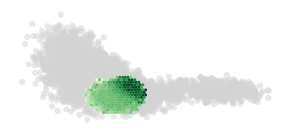

In [44]:
# plot PRRX1 expression
nx, figsize = 100, (3.5, 1.5)
fig, ax = plt.subplots(1, 1, figsize = figsize)
sc.pl.embedding(adata_dev, 'X_spectrum', size = 80, alpha = .5,
                frameon = False, show = False, ax = ax)
xlim = ax.get_xlim(); ylim = ax.get_ylim()
x, y = adata.obs[['late', 'early']].values.T
c = adata[:, 'PRRX1'].X.copy()
ar_data = (xlim[1] - xlim[0]) / (ylim[1] - ylim[0])
ar_fig = (figsize[0] / figsize[1])
ny = int((nx / np.sqrt(3)) * (ar_data / ar_fig))
hb = ax.hexbin(x, y, c, gridsize = [nx, ny], vmax = .05,
               extent = [*xlim, *ylim], cmap = 'Greens',
               linewidths = 0, mincnt = 70)
ax.set_xlim(xlim); ax.set_ylim(ylim); ax.set_title('')

fn = os.path.join(pth_fig, 'regulation.pdf')
plt.savefig(fn, bbox_inches = 'tight')